# Improving the Employability of IT Students

## Research Results, Data Analysis, and Scientific Visualization

### Project Overview

This notebook analyzes student employability indicators, including professional experience, academic projects, internships, technical skills, communication skills, job applications, interview invitations, and job offers.

### Data Source and Limitations

The current dataset contains 8 synthetic demonstration records. These data are used to test the research workflow and demonstrate statistical analysis and visualization. They are not real survey responses and cannot be used to draw conclusions about the entire student population.

### Reproducibility

The analysis uses Python, pandas, NumPy, and a fixed random seed for bootstrap confidence intervals.

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "metrics_summary.csv"

# Load processed data
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Make sure Jupyter is running from the project's notebooks folder "
        "and src/process_data.py has been executed."
    )

df = pd.read_csv(DATA_PATH)

# Exclude the overall summary row from student-level analysis
if "student_id" in df.columns:
    df = df[df["student_id"].astype(str).str.upper() != "OVERALL"].copy()

print("Dataset loaded successfully.")
print(f"Number of student records: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(f"Random seed: {RANDOM_SEED}")
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully.
Number of student records: 8
Number of columns: 11
Random seed: 42

Column names:
['student_id', 'professional_experience', 'academic_projects', 'internship', 'technical_skills', 'communication_skills', 'applications_sent', 'interview_invitations', 'job_offers', 'interview_invitation_rate', 'job_offer_rate_per_application']

First five records:


,student_id,professional_experience,academic_projects,internship,technical_skills,communication_skills,applications_sent,interview_invitations,job_offers,interview_invitation_rate,job_offer_rate_per_application
0,S01,no,2.0,no,3.0,4.0,12,1,0,0.083333,0.000000
1,S02,no,4.0,yes,4.0,4.0,20,4,1,0.200000,0.050000
2,S03,yes,3.0,yes,4.0,3.0,15,3,1,0.200000,0.066667
3,S04,no,1.0,no,2.0,3.0,18,0,0,0.000000,0.000000
4,S05,yes,5.0,yes,5.0,4.0,25,6,2,0.240000,0.080000



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      8 non-null      str    
 1   professional_experience         8 non-null      str    
 2   academic_projects               8 non-null      float64
 3   internship                      8 non-null      str    
 4   technical_skills                8 non-null      float64
 5   communication_skills            8 non-null      float64
 6   applications_sent               8 non-null      int64  
 7   interview_invitations           8 non-null      int64  
 8   job_offers                      8 non-null      int64  
 9   interview_invitation_rate       8 non-null      float64
 10  job_offer_rate_per_application  8 non-null      float64
dtypes: float64(5), int64(3), str(3)
memory usage: 836.0 bytes


In [2]:

# Check data quality
print("Dataset shape:", df.shape)

print("\nMissing values by column:")
display(df.isna().sum().to_frame(name="missing_values"))

print("\nNumber of duplicate student IDs:")
print(df["student_id"].duplicated().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumeric columns summary:")
display(df.describe().T)

# Check application consistency
quality_checks = {
    "Negative applications": (df["applications_sent"] < 0).sum(),
    "Negative interview invitations": (df["interview_invitations"] < 0).sum(),
    "Negative job offers": (df["job_offers"] < 0).sum(),
    "Invitations exceeding applications": (
        df["interview_invitations"] > df["applications_sent"]
    ).sum(),
    "Offers exceeding applications": (
        df["job_offers"] > df["applications_sent"]
    ).sum(),
}

print("\nConsistency checks:")
display(pd.DataFrame(
    list(quality_checks.items()),
    columns=["check", "number_of_records"]
))


Dataset shape: (8, 11)

Missing values by column:


,missing_values
student_id,0
professional_experience,0
academic_projects,0
internship,0
technical_skills,0
communication_skills,0
applications_sent,0
interview_invitations,0
job_offers,0
interview_invitation_rate,0



Number of duplicate student IDs:
0

Duplicate rows:
0

Numeric columns summary:


,count,mean,std,min,25%,50%,75%,max
academic_projects,8.0,3.000000,1.309307,1.0,2.000000,3.000000,4.000000,5.00
technical_skills,8.0,3.625000,0.916125,2.0,3.000000,4.000000,4.000000,5.00
communication_skills,8.0,3.500000,0.925820,2.0,3.000000,3.500000,4.000000,5.00
applications_sent,8.0,17.250000,5.035588,10.0,14.250000,17.000000,20.500000,25.00
interview_invitations,8.0,2.750000,1.982062,0.0,1.000000,3.000000,4.000000,6.00
job_offers,8.0,0.750000,0.707107,0.0,0.000000,1.000000,1.000000,2.00
interview_invitation_rate,8.0,0.149081,0.080139,0.0,0.095833,0.184659,0.200000,0.24
job_offer_rate_per_application,8.0,0.038078,0.033204,0.0,0.000000,0.047727,0.063542,0.08



Consistency checks:


,check,number_of_records
0,Negative applications,0
1,Negative interview invitations,0
2,Negative job offers,0
3,Invitations exceeding applications,0
4,Offers exceeding applications,0


In [3]:

# Descriptive statistics and bootstrap confidence intervals

BOOTSTRAP_ITERATIONS = 5000
rng = np.random.default_rng(RANDOM_SEED)

metrics = [
    "interview_invitation_rate",
    "job_offer_rate_per_application",
]

def bootstrap_mean_ci(values, iterations=BOOTSTRAP_ITERATIONS, confidence=0.95):
    """Estimate a confidence interval for the mean using bootstrap resampling."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    bootstrap_means = np.array([
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(iterations)
    ])

    alpha = 1 - confidence
    lower = np.quantile(bootstrap_means, alpha / 2)
    upper = np.quantile(bootstrap_means, 1 - alpha / 2)

    return lower, upper


statistics_rows = []

for metric in metrics:
    values = df[metric].dropna().to_numpy(dtype=float)

    ci_lower, ci_upper = bootstrap_mean_ci(values)

    statistics_rows.append({
        "metric": metric,
        "n": len(values),
        "mean": np.mean(values) if len(values) else np.nan,
        "median": np.median(values) if len(values) else np.nan,
        "p95": np.quantile(values, 0.95) if len(values) else np.nan,
        "p99": np.quantile(values, 0.99) if len(values) else np.nan,
        "std_dev": np.std(values, ddof=1) if len(values) > 1 else np.nan,
        "bootstrap_95ci_lower": ci_lower,
        "bootstrap_95ci_upper": ci_upper,
    })

stats_df = pd.DataFrame(statistics_rows)

print("Descriptive statistics")
display(stats_df.round(4))

print(
    "\nImportant: these estimates describe only the current "
    "synthetic demonstration dataset of 8 records."
)


Descriptive statistics


,metric,n,mean,median,p95,p99,std_dev,bootstrap_95ci_lower,bootstrap_95ci_upper
0,interview_invitation_rate,8,0.1491,0.1847,0.2260,0.2372,0.0801,0.0939,0.1987
1,job_offer_rate_per_application,8,0.0381,0.0477,0.0753,0.0791,0.0332,0.0162,0.0589



Important: these estimates describe only the current synthetic demonstration dataset of 8 records.


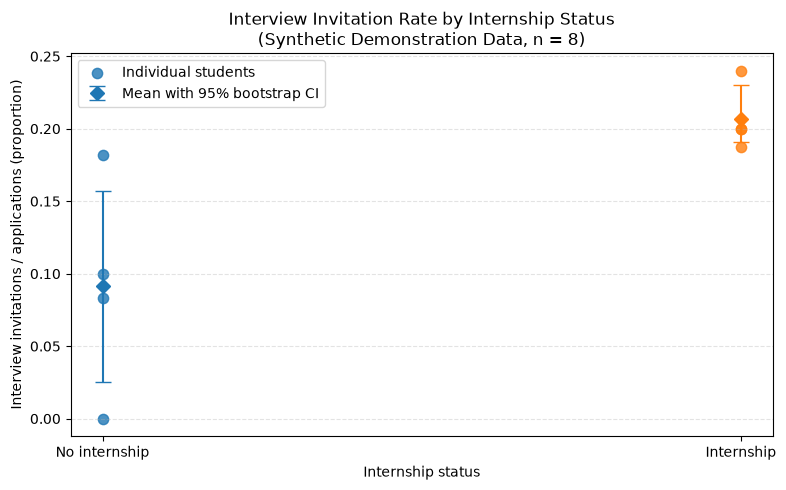

In [4]:

import matplotlib.pyplot as plt

# Compare interview invitation rates by internship status
group_order = ["no", "yes"]
group_labels = ["No internship", "Internship"]

fig, ax = plt.subplots(figsize=(8, 5))

for x_pos, group in enumerate(group_order):
    values = df.loc[
        df["internship"].astype(str).str.lower() == group,
        "interview_invitation_rate"
    ].dropna().to_numpy(dtype=float)

    if len(values) == 0:
        continue

    mean_value = values.mean()
    ci_lower, ci_upper = bootstrap_mean_ci(values)

    # Individual student observations
    ax.scatter(
        np.full(len(values), x_pos),
        values,
        s=55,
        alpha=0.8,
        label="Individual students" if x_pos == 0 else None
    )

    # Mean and bootstrap 95% confidence interval
    ax.errorbar(
        x_pos,
        mean_value,
        yerr=[[mean_value - ci_lower], [ci_upper - mean_value]],
        fmt="D",
        capsize=6,
        markersize=7,
        label="Mean with 95% bootstrap CI" if x_pos == 0 else None
    )

ax.set_xticks(range(len(group_labels)))
ax.set_xticklabels(group_labels)
ax.set_ylabel("Interview invitations / applications (proportion)")
ax.set_xlabel("Internship status")
ax.set_title(
    "Interview Invitation Rate by Internship Status\n"
    "(Synthetic Demonstration Data, n = 8)"
)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend()
fig.tight_layout()

plt.show()


In [5]:

# Save Figure 1 as PNG and PDF

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "fig1_internship_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig1_internship_comparison.pdf",
    bbox_inches="tight"
)

print("Figure 1 saved successfully.")
print("PNG:", FIGURES_DIR / "fig1_internship_comparison.png")
print("PDF:", FIGURES_DIR / "fig1_internship_comparison.pdf")


Figure 1 saved successfully.
PNG: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\reports\figures\fig1_internship_comparison.png
PDF: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\reports\figures\fig1_internship_comparison.pdf


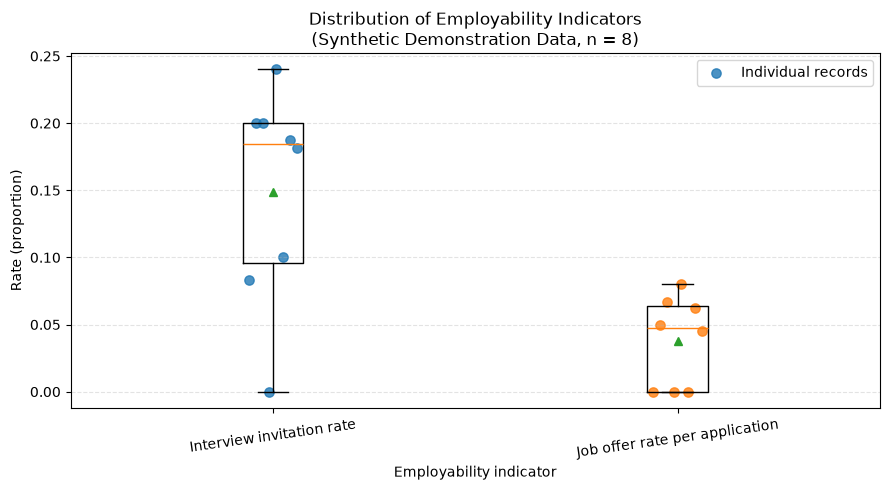

In [6]:

# Figure 2: Distribution of employability indicators

fig2, ax2 = plt.subplots(figsize=(9, 5))

distribution_data = [
    df["interview_invitation_rate"].dropna().to_numpy(dtype=float),
    df["job_offer_rate_per_application"].dropna().to_numpy(dtype=float),
]

labels = [
    "Interview invitation rate",
    "Job offer rate per application",
]

# Boxplots with individual observations
ax2.boxplot(
    distribution_data,
    tick_labels=labels,
    patch_artist=False,
    showmeans=True
)

for position, values in enumerate(distribution_data, start=1):
    # Small horizontal offsets make overlapping observations easier to see
    offsets = np.linspace(-0.06, 0.06, len(values))
    ax2.scatter(
        position + offsets,
        values,
        alpha=0.8,
        s=45,
        label="Individual records" if position == 1 else None
    )

ax2.set_ylabel("Rate (proportion)")
ax2.set_xlabel("Employability indicator")
ax2.set_title(
    "Distribution of Employability Indicators\n"
    "(Synthetic Demonstration Data, n = 8)"
)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.tick_params(axis="x", rotation=8)
ax2.legend()
fig2.tight_layout()

plt.show()


In [7]:

# Save Figure 2 as PNG and PDF

fig2.savefig(
    FIGURES_DIR / "fig2_rate_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

fig2.savefig(
    FIGURES_DIR / "fig2_rate_distributions.pdf",
    bbox_inches="tight"
)

print("Figure 2 saved successfully.")
print("PNG:", FIGURES_DIR / "fig2_rate_distributions.png")
print("PDF:", FIGURES_DIR / "fig2_rate_distributions.pdf")


Figure 2 saved successfully.
PNG: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\reports\figures\fig2_rate_distributions.png
PDF: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\reports\figures\fig2_rate_distributions.pdf


In [8]:

# Save statistical results and data quality checks

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save descriptive statistics
stats_path = RESULTS_DIR / "statistical_summary.csv"
stats_df.to_csv(stats_path, index=False)

# Save data quality checks
quality_df = pd.DataFrame(
    [
        {
            "check": check,
            "number_of_records": int(count),
        }
        for check, count in quality_checks.items()
    ]
)

quality_df["data_type"] = "synthetic_demo"
quality_df["interpretation"] = (
    "Demonstration only; do not generalize to the student population."
)

quality_path = RESULTS_DIR / "data_quality_summary.csv"
quality_df.to_csv(quality_path, index=False)

print("Results saved successfully.")
print(f"Statistical summary: {stats_path}")
print(f"Data quality summary: {quality_path}")
print("\nStatistical summary preview:")
display(stats_df.round(4))
print("\nData quality summary:")
display(quality_df)


Results saved successfully.
Statistical summary: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\results\statistical_summary.csv
Data quality summary: C:\Users\malik\OneDrive\Рабочий стол\it-student-employability-research\results\data_quality_summary.csv

Statistical summary preview:


,metric,n,mean,median,p95,p99,std_dev,bootstrap_95ci_lower,bootstrap_95ci_upper
0,interview_invitation_rate,8,0.1491,0.1847,0.2260,0.2372,0.0801,0.0939,0.1987
1,job_offer_rate_per_application,8,0.0381,0.0477,0.0753,0.0791,0.0332,0.0162,0.0589



Data quality summary:


,check,number_of_records,data_type,interpretation
0,Negative applications,0,synthetic_demo,Demonstration only; do not generalize to the s...
1,Negative interview invitations,0,synthetic_demo,Demonstration only; do not generalize to the s...
2,Negative job offers,0,synthetic_demo,Demonstration only; do not generalize to the s...
3,Invitations exceeding applications,0,synthetic_demo,Demonstration only; do not generalize to the s...
4,Offers exceeding applications,0,synthetic_demo,Demonstration only; do not generalize to the s...
